# 08. Human-in-the-Loop
## 학습 목표
- `interrupt()`로 실행을 멈추고 `Command(resume=...)`으로 재개한다.
- 승인 전에는 작업을 수행하지 않도록 Graph를 구성한다.

**실습 A**는 API 키 없이 실행된다. **실습 B**는 OpenAI API 키가 있을 때 Tool Calling 요청을 받아 모의 저장 도구로 연결한다. 실제 파일 저장이나 이메일 발송은 하지 않는다.

|핵심 | 코드	역할|
|----|-----|
|interrupt()	|Graph 실행을 중단하고 승인 요청을 전달|
|InMemorySaver()	|중단 시점의 상태를 메모리에 저장|
|thread_id	|중단된 실행을 식별|
|Command(resume=...)	|사람의 결정을 전달하고 실행 재개|
|add_conditional_edges()	|승인 여부에 따라 다음 Node 결정|

## 실습 A. 승인과 거절
실행 전 예측: `interrupt()`가 발생하면 `execute` Node가 이미 실행됐을까? 승인과 거절은 각각 어느 Node로 이동할까?

① interrupt()는 무엇을 하는가?

In [61]:
from pydantic import BaseModel
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import START, END, StateGraph
from langgraph.types import Command, interrupt

class ApprovalState(BaseModel):
    task: str               # 승인 요청된 작업의 설명
    status: str             # 현재 상태를 나타내는 문자열
    approved: bool          # 승인 여부를 나타내는 불리언 값

def prepare(state: ApprovalState) -> dict:
    return {"status": "승인 대기"}

def approval(state: ApprovalState) -> dict:
    # 중단 전에는 외부 작업 등 부작용을 실행하지 않는다.
    decision = interrupt(
        {"question": "작업을 실행할까요?", "task": state.task}
        )
    return {"approved": bool(decision)}

def route_approval(state: ApprovalState) -> str:
    return "execute" if state.approved else "cancel"

def execute(state: ApprovalState) -> dict:
    print("모의 작업 실행:", state.task)
    return {"status": "실행 완료"}

def cancel(state: ApprovalState) -> dict:
    print("작업 취소:", state.task)
    return {"status": "취소"}

builder = StateGraph(ApprovalState)
builder.add_node("prepare", prepare)
builder.add_node("approval", approval)
builder.add_node("execute", execute)
builder.add_node("cancel", cancel)

builder.add_edge(START, "prepare")
builder.add_edge("prepare", "approval")
builder.add_conditional_edges("approval", route_approval, {"execute": "execute", "cancel": "cancel"})
builder.add_edge("execute", END)
builder.add_edge("cancel", END)

# checkpointer를 InMemorySaver로 설정하여 그래프를 컴파일한다.
graph = builder.compile(checkpointer=InMemorySaver())

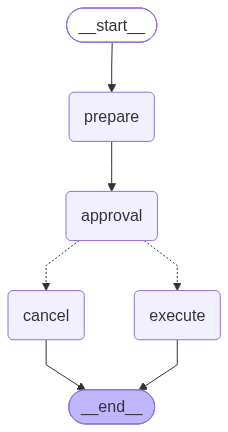

In [62]:
from IPython.display import Image, display

# PNG 생성에 네트워크 등이 필요하면 Mermaid 텍스트로 대체한다.
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as exc:
    print("PNG 시각화 불가:", type(exc).__name__)
    print(graph.get_graph().draw_mermaid())

② Checkpointer와 thread_id가 왜 필요한가?

In [70]:
# 같은 thread_id를 계속 써야 Checkpointer가 "어느 실행"인지 찾아 이어갈 수 있다.
yes_config = {"configurable": {"thread_id": "approve-demo"}}

# approval Node에서 interrupt()를 만나 실행이 멈춘다. invoke()는 끝까지 못 가고
# 멈춘 시점의 결과(State + __interrupt__ 정보)를 반환한다.
pending_yes = graph.invoke({"task": "보고서 저장 모의 실행", "status": "준비", "approved": False}, config=yes_config)

# __interrupt__ 키에 중단 당시 interrupt()에 넘겼던 payload(질문/작업 내용)가 담겨 있다.
pending_yes

{'task': '보고서 저장 모의 실행',
 'status': '승인 대기',
 'approved': False,
 '__interrupt__': [Interrupt(value={'question': '작업을 실행할까요?', 'task': '보고서 저장 모의 실행'}, id='8efda544254bc44752550753cc80bc0e', response_schema=None)]}

In [71]:
print("중단 요청:", [item.value for item in pending_yes["__interrupt__"]])

중단 요청: [{'question': '작업을 실행할까요?', 'task': '보고서 저장 모의 실행'}]


In [72]:
# approve-demo 스레드에 저장된 가장 최근 State 스냅샷을 꺼내서, 중단된 시점에 값이 어땠는지 출력
print("중단 시 State:", graph.get_state(yes_config).values)

# 테스트 코드
assert graph.get_state(yes_config).values["status"] == "승인 대기"

중단 시 State: {'task': '보고서 저장 모의 실행', 'status': '승인 대기', 'approved': False}


③ Command(resume=True)는 무엇인가?

In [73]:
# 최초 실행: interrupt()에서 중단

# 사람이 승인 또는 거절을 선택
answer = input("작업을 승인하시겠습니까? (y/n): ")
approved = answer.strip().lower() == "y"

# 선택 결과를 전달해 Graph 실행 재개 - Command(resume=True)
approved_result = graph.invoke(
    Command(resume=approved),
    config=yes_config
)

print("승인 후 최종 State:", approved_result)

# 테스트 코드
# 승인/거절 결과가 다르므로 분기해서 검증한다.
if approved_result["approved"]:
    assert approved_result["status"] == "실행 완료"
else:
    assert approved_result["status"] == "취소"

모의 작업 실행: 보고서 저장 모의 실행
승인 후 최종 State: {'task': '보고서 저장 모의 실행', 'status': '실행 완료', 'approved': True}


In [52]:
no_config = {"configurable": {"thread_id": "reject-demo"}}
pending_no = graph.invoke({"task": "이메일 발송 모의 실행", "status": "준비", "approved": False}, config=no_config)

print("중단 요청:", [item.value for item in pending_no["__interrupt__"]])

중단 요청: [{'question': '작업을 실행할까요?', 'task': '이메일 발송 모의 실행'}]


In [ ]:
# 승인 False 전달해 재개 - Command(resume=False), 재개할 thread_id는 no_config로 지정해야 한다.
rejected_result = graph.invoke(Command(resume=False), config=no_config)

print("거절 후 최종 State:", rejected_result)
assert rejected_result["status"] == "취소"

작업 취소: 이메일 발송 모의 실행
거절 후 최종 State: {'task': '이메일 발송 모의 실행', 'status': '취소', 'approved': False}


같은 `thread_id`로 재개해야 중단 위치를 찾는다.   
재개할 때 `interrupt()`가 있던 Node는 처음부터 다시 실행될 수 있으므로, 중단 이전에 저장·발송 같은 부작용을 두지 않는다.  

## 실습 B. Agent의 도구 실행 요청 승인
모델이 `save_report` 도구 호출을 **요청**한다. Graph는 호출 요청을 State에 담고 사람에게 묻는다. 승인 후에만 Python 모의 함수를 실행한다. API 키가 없으면 아래 셀은 건너뛰고 실습 A까지 학습한다.

In [54]:
import os
from dotenv import load_dotenv
load_dotenv()
has_api_key = bool(os.getenv("OPENAI_API_KEY"))
print("Agent 확장 실행 가능:", has_api_key)

Agent 확장 실행 가능: True


In [78]:
if has_api_key:
    from langchain_openai import ChatOpenAI
    from langchain_core.messages import HumanMessage
    from langchain_core.tools import tool

    @tool
    def save_report(title: str) -> str:
        """제목의 보고서를 저장한다. 이 실습에서는 실제 저장하지 않는다."""
        return f"모의 저장 완료: {title}"

    options = {"model": os.getenv("LLM_MODEL") or "gpt-4o-mini", "temperature": 0}
    if os.getenv("OPENAI_BASE_URL"):
        options["base_url"] = os.environ["OPENAI_BASE_URL"]
    # tool_choice로 save_report 호출을 강제한다. 모델이 매번 같은 도구를 선택하게 해
    # 데모 결과를 예측 가능하게 만들기 위함이다(실전에서는 보통 "auto"로 둔다).
    agent_llm = ChatOpenAI(**options).bind_tools([save_report], tool_choice="save_report", parallel_tool_calls=False)

    class AgentApprovalState(BaseModel):
        request: str           # 사용자가 Agent에게 보낸 요청 문장
        tool_call: dict = {}   # 모델이 생성한 도구 호출 요청(이름 + 인자)
        approved: bool         # 사람이 이 도구 호출을 승인했는지 여부
        result: str            # 최종 결과 문자열(실행 완료 또는 거절 메시지)

    def agent_request(state: AgentApprovalState) -> dict:
        # 여기서는 도구를 "실행"하지 않고, 모델이 어떤 도구를 어떤 인자로 부르고
        # 싶어하는지 요청(tool_calls)만 받아서 State에 저장해 둔다.
        reply = agent_llm.invoke([HumanMessage(content=state.request)])
        
        print("_node: 모델이 요청한 도구 호출:", reply.tool_calls[0])
        if not reply.tool_calls:
            raise ValueError("모델이 도구 호출을 요청하지 않았다. 제공자의 Tool Calling 지원 여부를 확인한다.")
        return {"tool_call": reply.tool_calls[0]}

    def review_call(state: AgentApprovalState) -> dict:
        # 실제 도구를 실행하기 전에 사람에게 승인을 구하고 여기서 멈춘다.
        # 모델이 요청만 만들고 사람이 집행 여부를 결정하는 구조다.
        call = state.tool_call
        decision = interrupt({"question": "이 모의 도구를 실행할까요?", "tool": call["name"], "args": call["args"]})
        return {"approved": bool(decision)}

    def run_mock_tool(state: AgentApprovalState) -> dict:
        # 승인된 경로에서만 도달하는 Node. 여기서만 실제로 도구를 호출한다.
        call = state.tool_call
        if call["name"] != "save_report":
            raise ValueError("허용되지 않은 도구")
        return {"result": save_report.invoke(call["args"])}

    def reject_call(state: AgentApprovalState) -> dict:
        # 거절된 경로. 도구를 호출하지 않고 거절 사실만 결과로 남긴다.
        return {"result": "사람이 도구 실행을 거절함"}

    # 조건부 분기 함수: approved 값에 따라 run_mock(실행) 또는 reject(거절)로 보낸다.
    def route_review(state: AgentApprovalState) -> str:
        return "run" if state.approved else "reject"

    agent_builder = StateGraph(AgentApprovalState)
    agent_builder.add_node("agent", agent_request)
    agent_builder.add_node("review", review_call)
    agent_builder.add_node("run_mock", run_mock_tool)
    agent_builder.add_node("reject", reject_call)
    agent_builder.add_edge(START, "agent")
    agent_builder.add_edge("agent", "review")
    # review 이후: 승인(run_mock)과 거절(reject) 두 갈래로만 나뉘고, 다른 경로로는 못 간다.
    agent_builder.add_conditional_edges("review", route_review, {"run": "run_mock", "reject": "reject"})
    agent_builder.add_edge("run_mock", END)
    agent_builder.add_edge("reject", END)
    # checkpointer가 있어야 review Node의 interrupt()에서 멈췄다가 나중에 재개할 수 있다.
    agent_graph = agent_builder.compile(checkpointer=InMemorySaver())
else:
    print("API 키가 없어 실습 B를 건너뛴다.")

In [79]:
if has_api_key:
    agent_config = {"configurable": {"thread_id": "agent-approval"}}
    # agent -> review까지 진행되고, review의 interrupt()에서 멈춘다.
    # 이 시점엔 아직 save_report가 호출되지 않았다(모델은 "요청"만 만들었다).
    pending = agent_graph.invoke({"request": "'10월 실습 결과' 보고서를 저장해줘.", "approved": False, "result": "미실행"}, config=agent_config)
    
    print("1. Agent 도구 요청:", agent_graph.get_state(agent_config).values["tool_call"])
    print("2. 승인 요청:", [item.value for item in pending["__interrupt__"]])
    print("승인 전 결과:", agent_graph.get_state(agent_config).values["result"])
    assert agent_graph.get_state(agent_config).values["result"] == "미실행"

    # 사람이 승인 또는 거절을 선택
    answer = input("작업을 승인하시겠습니까? (y/n): ")
    approved = answer.strip().lower() == "y"

    print("승인 여부:", approved)
    # Command(resume=approved)로 review Node의 interrupt() 지점부터 이어서 실행한다.
    # approved 값에 따라 route_review가 run_mock 또는 reject로 보낸다.
    completed = agent_graph.invoke(Command(resume=approved), config=agent_config)
    print("3. 승인 및 재개:", completed["approved"])
    print("4. 모의 도구 결과:", completed["result"])

    # 승인/거절 결과가 다르므로 분기해서 검증한다.
    if completed["approved"]:
        assert completed["result"].startswith("모의 저장 완료:")
    else:
        assert completed["result"] == "사람이 도구 실행을 거절함"
else:
    print("실습 B 미실행: OPENAI_API_KEY 없음")

_node: 모델이 요청한 도구 호출: {'name': 'save_report', 'args': {'title': '10월 실습 결과'}, 'id': 'call_SXpPaXJANBQ4lkHVbnWyTmXq', 'type': 'tool_call'}
1. Agent 도구 요청: {'name': 'save_report', 'args': {'title': '10월 실습 결과'}, 'id': 'call_SXpPaXJANBQ4lkHVbnWyTmXq', 'type': 'tool_call'}
2. 승인 요청: [{'question': '이 모의 도구를 실행할까요?', 'tool': 'save_report', 'args': {'title': '10월 실습 결과'}}]
승인 전 결과: 미실행
승인 여부: False
3. 승인 및 재개: False
4. 모의 도구 결과: 사람이 도구 실행을 거절함


## 이해 확인
1. 승인 전 도구 실행을 막는 위치는 어디인가?  
   **해설:** `review_call`의 `interrupt()` 이후 승인 경로에서만 `run_mock_tool`에 진입한다.
2. `interrupt()` 앞에서 이메일을 먼저 보내면 왜 위험한가?  
   **해설:** 승인 전 부작용이 발생하고, 재개 시 Node 앞부분이 재실행되어 중복 발송될 수 있다.

**핵심 정리:** 모델에게 요청 생성 권한을 주더라도 실제 작업 실행은 Checkpoint와 사람의 승인으로 통제할 수 있다.